<a href="https://colab.research.google.com/github/Prktriesitout/pandas_assignment/blob/main/PandasAssignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv('reviews.csv')

In [ ]:
reviews = df.copy()

In [ ]:
reviews = reviews.set_index('title')
display(reviews.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,variety,winery
title,,,,,,,,,,,,,
Nicosia 2013 Vulkà Bianco (Etna),0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,White Blend,Nicosia
Quinta dos Avidagos 2011 Avidagos Red (Douro),1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Portuguese Red,Quinta dos Avidagos
Rainstorm 2013 Pinot Gris (Willamette Valley),2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Pinot Gris,Rainstorm
St. Julian 2013 Reserve Late Harvest Riesling (Lake Michigan Shore),3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,Riesling,St. Julian
Sweet Cheeks 2012 Vintner's Reserve Wild Child Block Pinot Noir (Willamette Valley),4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Pinot Noir,Sweet Cheeks


Setting the 'title' column as the index changes how data selection behaves, particularly when using `.loc[]`.

*   **Integer-location based indexing (`.iloc[]`)**: This method still works with integer positions (0, 1, 2, ...), regardless of the index label. Its behavior remains unchanged.

*   **Label-location based indexing (`.loc[]`)**: This method now uses the values in the 'title' column for selection instead of the default integer index. You can select rows directly by their title.

*   **Direct indexing (`[]`)**: While direct indexing can still be used for column selection, when used for row selection, it now expects an index label (a title in this case) rather than an integer position (unless the index is still integer-based and unambiguous). However, for consistency and clarity, it's generally best practice to use `.loc[]` for label-based row selection and `.iloc[]` for integer-based row selection.

## Conditional Selection

Select all reviews where the country is "Italy" and points are greater than 90. Display the first five results.

In [ ]:
italy_high_points = df[(df['country'] == 'Italy') & (df['points'] > 90)]
display(italy_high_points.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
120,120,Italy,"Slightly backward, particularly given the vint...",Bricco Rocche Prapó,92,70.0,Piedmont,Barolo,NaN,NaN,NaN,Ceretto 2003 Bricco Rocche Prapó (Barolo),Nebbiolo,Ceretto
130,130,Italy,"At the first it was quite muted and subdued, b...",Bricco Rocche Brunate,91,70.0,Piedmont,Barolo,NaN,NaN,NaN,Ceretto 2003 Bricco Rocche Brunate (Barolo),Nebbiolo,Ceretto
133,133,Italy,"Einaudi's wines have been improving lately, an...",NaN,91,68.0,Piedmont,Barolo,NaN,NaN,NaN,Poderi Luigi Einaudi 2003 Barolo,Nebbiolo,Poderi Luigi Einaudi
135,135,Italy,The color is just beginning to show signs of b...,Sorano,91,60.0,Piedmont,Barolo,NaN,NaN,NaN,Giacomo Ascheri 2001 Sorano (Barolo),Nebbiolo,Giacomo Ascheri
158,158,Italy,"Baked plum, Asian spice, vanilla and menthol a...",Bellezza Gran Selezione,91,38.0,Tuscany,Chianti Classico,NaN,Kerin O’Keefe,@kerinokeefe,Castello di Gabbiano 2012 Bellezza Gran Selezi...,Sangiovese,Castello di Gabbiano


## Column Selection

Retrieve only the country, points, and price columns for the first 10 rows.

In [ ]:
selected_columns = df.loc[0:9, ['country', 'points', 'price']]
display(selected_columns)

,country,points,price
0,Italy,87,NaN
1,Portugal,87,15.0
2,US,87,14.0
3,US,87,13.0
4,US,87,65.0
5,Spain,87,15.0
6,Italy,87,16.0
7,France,87,24.0
8,Germany,87,12.0
9,France,87,27.0


## GroupBy - Aggregation: Average Points and Price by Country

In [ ]:
country_stats = df.groupby('country').agg(
    avg_points=('points', 'mean'),
    avg_price=('price', 'mean')
)
display(country_stats.head())

,avg_points,avg_price
country,,
Argentina,86.710263,24.510117
Armenia,87.500000,14.500000
Australia,88.580507,35.437663
Austria,90.101345,30.762772
Bosnia and Herzegovina,86.500000,12.500000


## GroupBy - Multi-Index: Count Reviews by Country and Province

In [ ]:
country_province_counts = df.groupby(['country', 'province']).size().reset_index(name='review_count')
display(country_province_counts.head())

,country,province,review_count
0,Argentina,Mendoza Province,3264
1,Argentina,Other,536
2,Armenia,Armenia,2
3,Australia,Australia Other,245
4,Australia,New South Wales,85


## Aggregate Function: Min, Max, and Average Price by Variety

In [ ]:
variety_price_stats = df.groupby('variety').agg(
    min_price=('price', 'min'),
    max_price=('price', 'max'),
    avg_price=('price', 'mean')
)
display(variety_price_stats.head())

,min_price,max_price,avg_price
variety,,,
Abouriou,15.0,75.0,35.000000
Agiorgitiko,10.0,66.0,23.571429
Aglianico,6.0,180.0,38.887755
Aidani,27.0,27.0,27.000000
Airen,8.0,10.0,9.000000


## Pivot Table - Mean Points by Country and Variety

In [ ]:
pivot_mean_points = df.pivot_table(values='points', index='country', columns='variety', aggfunc='mean')
display(pivot_mean_points.head())

variety,Abouriou,Agiorgitiko,Aglianico,Aidani,Airen,Albana,Albanello,Albariño,Albarossa,Aleatico,...,Yapincak,Zelen,Zibibbo,Zierfandler,Zierfandler-Rotgipfler,Zinfandel,Zlahtina,Zweigelt,Çalkarası,Žilavka
country,,,,,,,,,,,,,,,,,,,,,
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Armenia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,88.333333,NaN,NaN,NaN,NaN
Austria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,90.1875,90.4,NaN,NaN,88.293532,NaN,NaN
Bosnia and Herzegovina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Pivot Table - Fill Missing Values: Average Price by Country and Province (NaN as 0)

In [ ]:
pivot_avg_price_filled = df.pivot_table(values='price', index='country', columns='province', aggfunc='mean', fill_value=0)
display(pivot_avg_price_filled.head())

province,Achaia,Aconcagua Costa,Aconcagua Valley,Aegean,Agioritikos,Ahr,Alenquer,Alentejano,Alentejo,Alenteo,...,Wellington,Western Australia,Western Cape,Wiener Gemischter Satz,Württemberg,Zenata,Österreichischer Perlwein,Österreichischer Sekt,Štajerska,Župa
country,,,,,,,,,,,,,,,,,,,,,
Argentina,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.00,0.0,0.0,0.00,0.000000,0.0,0.0
Armenia,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.00,0.0,0.0,0.00,0.000000,0.0,0.0
Australia,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,33.578947,0.0,0.00,0.0,0.0,0.00,0.000000,0.0,0.0
Austria,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,27.88,0.0,0.0,16.75,27.983607,0.0,0.0
Bosnia and Herzegovina,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.00,0.0,0.0,0.00,0.000000,0.0,0.0


## Top Varieties by Country: United States

In [ ]:
us_wines = df[df['country'] == 'US']
top_us_varieties = us_wines['variety'].value_counts().head(5)
display(top_us_varieties)

,count
variety,
Pinot Noir,9885
Cabernet Sauvignon,7315
Chardonnay,6801
Syrah,3244
Red Blend,2972


## Top Rated Wines: Points > 95 and Price > 100

In [ ]:
top_rated_wines = df[(df['points'] > 95) & (df['price'] > 100)]
display(top_rated_wines.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
345,345,Australia,This wine contains some material over 100 year...,Rare,100,350.0,Victoria,Rutherglen,NaN,Joe Czerwinski,@JoeCz,Chambers Rosewood Vineyards NV Rare Muscat (Ru...,Muscat,Chambers Rosewood Vineyards
346,346,Australia,"This deep brown wine smells like a damp, mossy...",Rare,98,350.0,Victoria,Rutherglen,NaN,Joe Czerwinski,@JoeCz,Chambers Rosewood Vineyards NV Rare Muscadelle...,Muscadelle,Chambers Rosewood Vineyards
347,347,Germany,"Dusty, saffron-spiced earthiness is juxtaposed...",Kiedrich Gräfenberg Trockenbeerenauslese,97,775.0,Rheingau,NaN,NaN,Anna Lee C. Iijima,NaN,Robert Weil 2014 Kiedrich Gräfenberg Trockenbe...,Riesling,Robert Weil
349,349,Australia,"RunRig is always complex, and the 2012 doesn't...",RunRig,97,225.0,South Australia,Barossa,NaN,Joe Czerwinski,@JoeCz,Torbreck 2012 RunRig Shiraz-Viognier (Barossa),Shiraz-Viognier,Torbreck
350,350,Italy,"After a few minutes in the glass, this stunnin...",Vignolo Riserva,97,150.0,Piedmont,Barolo,NaN,Kerin O’Keefe,@kerinokeefe,Cavallotto 2010 Vignolo Riserva (Barolo),Nebbiolo,Cavallotto


## Imputation: Fill Missing Price Values with Median Price by Country

In [ ]:
df['price'] = df.groupby('country')['price'].transform(lambda x: x.fillna(x.median()))

# Check for remaining missing values in 'price' (should be very few, only for countries with all prices missing)
missing_prices_after_imputation = df['price'].isnull().sum()
print(f"Number of missing prices after imputation: {missing_prices_after_imputation}")

display(df.head())

Number of missing prices after imputation: 64


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


## Dropping Rows: Remove rows with missing 'taster_name'

In [ ]:
initial_rows = len(df)
df_cleaned_taster = df.dropna(subset=['taster_name'])
removed_rows = initial_rows - len(df_cleaned_taster)

print(f"Initial number of rows: {initial_rows}")
print(f"Number of rows after dropping NaNs in 'taster_name': {len(df_cleaned_taster)}")
print(f"Number of rows removed: {removed_rows}")

display(df_cleaned_taster.head())

Initial number of rows: 129971
Number of rows after dropping NaNs in 'taster_name': 103727
Number of rows removed: 26244


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


## Forward Fill: Impute Missing 'region_2' Values

In [ ]:
print(f"Missing 'region_2' values BEFORE ffill: {df_cleaned_taster['region_2'].isnull().sum()}")

df_cleaned_taster['region_2'] = df_cleaned_taster['region_2'].ffill()

print(f"Missing 'region_2' values AFTER ffill: {df_cleaned_taster['region_2'].isnull().sum()}")
display(df_cleaned_taster.head())

Missing 'region_2' values BEFORE ffill: 68960
Missing 'region_2' values AFTER ffill: 2


/tmp/ipykernel_2131/123527917.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned_taster['region_2'] = df_cleaned_taster['region_2'].ffill()


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,Willamette Valley,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


## DataFrame Merge: GDP and Wine Data Analysis

In [ ]:
# Select all columns and the first 50 rows from the original 'df'
df_subset = df.iloc[:50].copy()

# Display the head of the subset DataFrame to verify
display(df_subset.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [ ]:
df1=pd.read_csv("country_GDP.csv")

The `country_GDP.csv` file has already been loaded into `df1` in the previous step.

In [ ]:
# Rename 'Country' column in df1 to 'country' to match df_subset
df1 = df1.rename(columns={'Country': 'country'})

# Merge df_subset and df1 on the 'country' column
merged_df = pd.merge(df_subset, df1, on='country', how='left')

# Display the merged DataFrame to analyze the relationship between GDP and wine prices
display(merged_df.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery,GDP
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,2.1
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,NaN
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,NaN
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,NaN
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,NaN


## Lambda - Price Category

In [ ]:
# Create a new column 'price_category' using a lambda function
merged_df['price_category'] = merged_df['price'].apply(lambda x: 'Low' if x < 20 else ('Medium' if 20 <= x <= 50 else ('High' if 50 < x <= 100 else 'Premium')))

# Display the DataFrame with the new 'price_category' column
display(merged_df.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery,GDP,price_category
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,2.1,Medium
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,NaN,Low
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,NaN,Low
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,NaN,Low
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,NaN,High


## Lambda - Title Length

In [ ]:
# Add a new column 'title_length' using a lambda function
# Note: Assuming 'title' column exists and is a string type
merged_df['title_length'] = merged_df['title'].apply(lambda x: len(str(x)))

# Display the DataFrame with the new 'title_length' column
display(merged_df.head())

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery,GDP,price_category,title_length
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,28.0,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,2.1,Medium,33
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,NaN,Low,45
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,NaN,Low,45
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,NaN,Low,67
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,NaN,High,83


## KDE Plot for Points Distribution

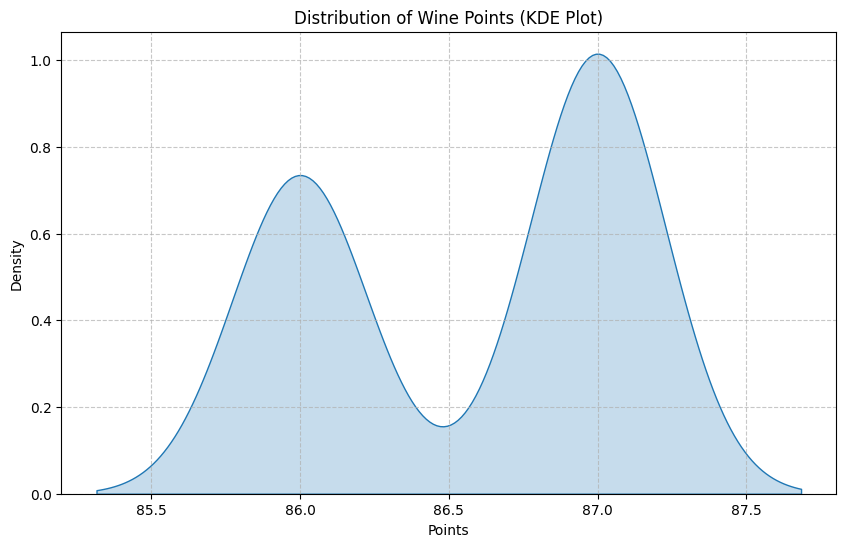

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a KDE plot for the 'points' column
plt.figure(figsize=(10, 6))
sns.kdeplot(merged_df['points'], fill=True)
plt.title('Distribution of Wine Points (KDE Plot)')
plt.xlabel('Points')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Description of Points Distribution

The Kernel Density Estimate (KDE) plot visually represents the probability density function of the 'points' column.

Based on the plot:
*   **Shape**: The distribution appears to be left-skewed, meaning there is a longer tail on the left side, and the majority of the data points are concentrated towards higher values.
*   **Peak**: The peak of the distribution is likely around 88-90 points, indicating that most wines in the dataset receive scores in this range.
*   **Range**: The points generally range from around 80 to 100, with very few wines scoring below 80.

## Distribution Plot: Price Column

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a distribution plot for the 'price' column
plt.figure(figsize=(12, 7))
sns.histplot(merged_df['price'], kde=True, bins=50, color='skyblue')
plt.title('Distribution of Wine Prices')
plt.xlabel('Price')
plt.ylabel('Frequency / Density')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xlim(0, merged_df['price'].max())
plt.show()

### Interpretation of Wine Pricing Distribution

The distribution plot (histogram with KDE) for the 'price' column reveals several key characteristics about the pricing of wines in our dataset:

*   **Right-Skewed Distribution**: The plot shows a heavily right-skewed (or positively skewed) distribution. This means that the majority of wines are priced at the lower end of the spectrum, with a long tail extending towards higher prices.
*   **Concentration of Lower Prices**: There's a very high frequency of wines in the lower price ranges, likely below $50, with a significant peak around the $20-$30 mark. This indicates that most wines in the dataset are relatively affordable.
*   **Few High-Priced Wines**: As the price increases, the frequency of wines drops sharply. There are progressively fewer wines available at higher price points, and very few wines that are extremely expensive (e.g., above $100-$200).
*   **Outliers**: The long tail on the right suggests the presence of some expensive or premium wines, which are outliers compared to the bulk of the wines in terms of price.

In summary, the wine market represented in this dataset is dominated by lower to moderately priced wines, with a smaller selection of high-end, premium offerings.